# Model Evaluation and Validation

A model that scores well on one metric is not automatically useful. This notebook builds a practical
evaluation toolkit for classification and regression:

- confusion matrix, precision, recall, F1
- ROC curves and ROC-AUC
- precision-recall curves and PR-AUC
- cross-validation with `KFold` and `StratifiedKFold`
- learning curves
- regression metrics: MAE, MSE, RMSE, and R²
- common pitfalls such as data leakage and optimising a metric that does not match the problem

## Learning objectives

1. Choose an evaluation metric that matches the real-world cost of errors.
2. Compute and interpret classification and regression metrics.
3. Use cross-validation correctly and report variability.
4. Read ROC and precision-recall curves.
5. Diagnose underfitting and overfitting with a learning curve.

## 1. Metric selection

| Problem | Good default metric | Why |
| --- | --- | --- |
| Balanced classification | Accuracy | Simple and intuitive |
| Imbalanced classification | PR-AUC, F1, recall | Accuracy hides the minority class |
| Ranking / probability quality | ROC-AUC | Threshold-independent ranking quality |
| Regression, typical error | MAE | Same units as the target |
| Regression, large errors matter more | RMSE | Penalises large residuals |
| Regression, variance explained | R² | Scale-free comparison |

The metric must reflect the cost of mistakes. In medical screening, a false negative can be much more
expensive than a false positive, so recall deserves attention even if accuracy drops.

## 2. Setup

In [1]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

from sklearn.datasets import load_breast_cancer, load_diabetes
from sklearn.linear_model import LinearRegression, LogisticRegression
from sklearn.metrics import (
    ConfusionMatrixDisplay,
    PrecisionRecallDisplay,
    RocCurveDisplay,
    accuracy_score,
    classification_report,
    confusion_matrix,
    f1_score,
    mean_absolute_error,
    mean_squared_error,
    precision_score,
    r2_score,
    recall_score,
    roc_auc_score,
    average_precision_score,
)
from sklearn.model_selection import (
    KFold,
    StratifiedKFold,
    cross_val_score,
    cross_validate,
    learning_curve,
    train_test_split,
)
from sklearn.pipeline import Pipeline
from sklearn.preprocessing import StandardScaler

RANDOM_STATE = 42
np.random.seed(RANDOM_STATE)
sns.set_theme(style="whitegrid")

## 3. Classification metrics on the breast-cancer dataset

In [2]:
data = load_breast_cancer(as_frame=True)
X, y = data.data, data.target

X_train, X_test, y_train, y_test = train_test_split(
    X, y, test_size=0.25, random_state=RANDOM_STATE, stratify=y
)

model = Pipeline([
    ("scaler", StandardScaler()),
    ("model", LogisticRegression(max_iter=5000, random_state=RANDOM_STATE)),
])
model.fit(X_train, y_train)
y_pred = model.predict(X_test)
y_prob = model.predict_proba(X_test)[:, 1]

metrics = {
    "accuracy": accuracy_score(y_test, y_pred),
    "precision": precision_score(y_test, y_pred),
    "recall": recall_score(y_test, y_pred),
    "f1": f1_score(y_test, y_pred),
    "roc_auc": roc_auc_score(y_test, y_prob),
    "pr_auc": average_precision_score(y_test, y_prob),
}
pd.DataFrame([metrics]).round(4)

,accuracy,precision,recall,f1,roc_auc,pr_auc
0,0.986,0.9889,0.9889,0.9889,0.9977,0.9986


              precision    recall  f1-score   support

   malignant       0.98      0.98      0.98        53
      benign       0.99      0.99      0.99        90

    accuracy                           0.99       143
   macro avg       0.99      0.99      0.99       143
weighted avg       0.99      0.99      0.99       143



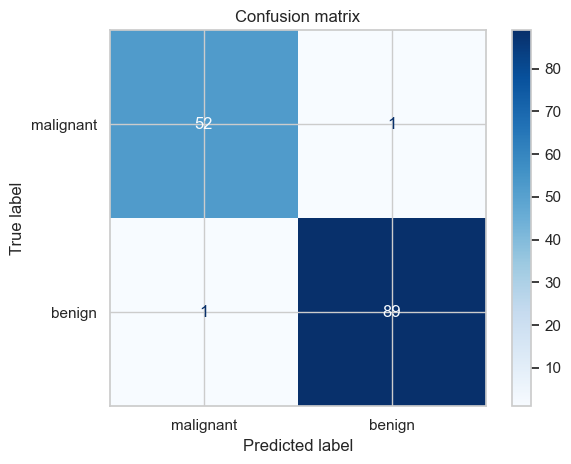

In [3]:
print(classification_report(y_test, y_pred, target_names=data.target_names))

ConfusionMatrixDisplay.from_predictions(
    y_test, y_pred, display_labels=data.target_names, cmap="Blues"
)
plt.title("Confusion matrix")
plt.tight_layout()
plt.show()

### Reading the confusion matrix

- **True positive (TP)**: correctly predicted positive.
- **True negative (TN)**: correctly predicted negative.
- **False positive (FP)**: predicted positive, actually negative (false alarm).
- **False negative (FN)**: predicted negative, actually positive (missed case).

Precision is $TP / (TP + FP)$: how often a positive prediction is correct.
Recall is $TP / (TP + FN)$: how many real positives we found.
F1 is the harmonic mean of precision and recall.

## 4. ROC and precision-recall curves

ROC plots true-positive rate against false-positive rate at every threshold. PR plots precision
against recall. PR curves are usually more informative when the positive class is rare.

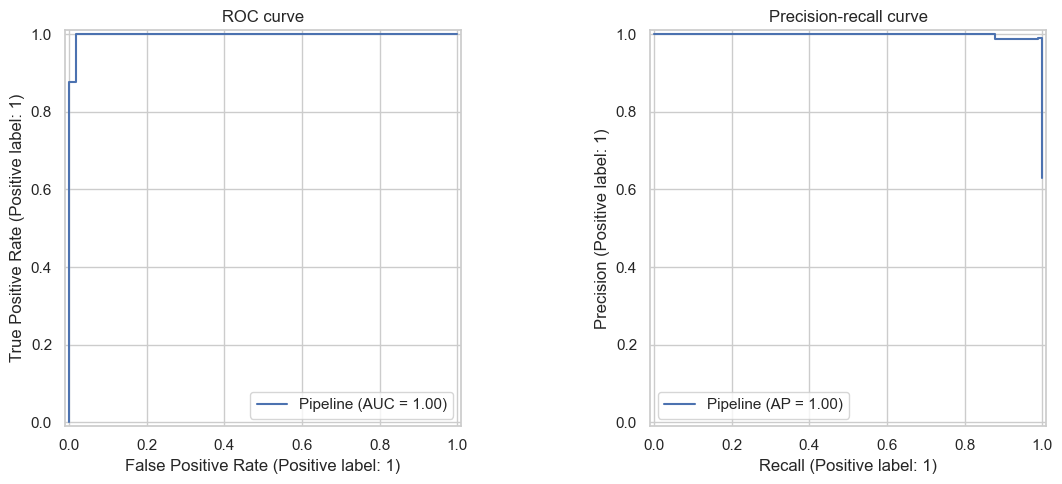

In [4]:
fig, axes = plt.subplots(1, 2, figsize=(12, 5))

RocCurveDisplay.from_estimator(model, X_test, y_test, ax=axes[0])
axes[0].set_title("ROC curve")

PrecisionRecallDisplay.from_estimator(model, X_test, y_test, ax=axes[1])
axes[1].set_title("Precision-recall curve")

plt.tight_layout()
plt.show()

### Threshold tuning

`predict()` uses a 0.5 threshold by default. Lowering the threshold usually increases recall and
decreases precision. The right threshold depends on the application and the relative cost of errors.

In [5]:
thresholds = np.arange(0.1, 0.91, 0.1)
rows = []
for threshold in thresholds:
    pred = (y_prob >= threshold).astype(int)
    rows.append({
        "threshold": round(threshold, 1),
        "precision": precision_score(y_test, pred, zero_division=0),
        "recall": recall_score(y_test, pred, zero_division=0),
        "f1": f1_score(y_test, pred, zero_division=0),
    })
pd.DataFrame(rows).round(3)

,threshold,precision,recall,f1
0,0.1,0.928,1.000,0.963
1,0.2,0.957,1.000,0.978
2,0.3,0.968,1.000,0.984
3,0.4,0.989,0.989,0.989
4,0.5,0.989,0.989,0.989
5,0.6,0.988,0.944,0.966
6,0.7,0.988,0.933,0.960
7,0.8,0.988,0.933,0.960
8,0.9,1.000,0.878,0.935


## 5. Cross-validation

A single train/test split is noisy. Cross-validation repeats the split and reports the mean and
standard deviation of the score.

- Use `StratifiedKFold` for classification so every fold keeps the class balance.
- Use `KFold(shuffle=True)` for regression.
- Use `TimeSeriesSplit` for time-ordered data (covered in the time-series notebook).
- Never preprocess using the full dataset before cross-validation; put preprocessing inside a pipeline.

In [6]:
cv = StratifiedKFold(n_splits=5, shuffle=True, random_state=RANDOM_STATE)
scores = cross_val_score(model, X, y, cv=cv, scoring="accuracy", n_jobs=-1)
print("Fold accuracies:", np.round(scores, 4))
print(f"Mean accuracy: {scores.mean():.4f} (+/- {scores.std():.4f})")

Fold accuracies: [0.9737 0.9474 0.9649 0.9912 0.9912]
Mean accuracy: 0.9737 (+/- 0.0166)


In [7]:
scoring = ["accuracy", "precision", "recall", "f1", "roc_auc"]
cv_results = cross_validate(model, X, y, cv=cv, scoring=scoring, n_jobs=-1)
summary = pd.DataFrame({
    metric: [cv_results[f"test_{metric}"].mean(), cv_results[f"test_{metric}"].std()]
    for metric in scoring
}, index=["mean", "std"]).T
summary.round(4)

,mean,std
accuracy,0.9737,0.0166
precision,0.9683,0.0290
recall,0.9916,0.0112
f1,0.9794,0.0127
roc_auc,0.9953,0.0053


## 6. Learning curves

A learning curve shows training and validation performance as the training set grows.

- Both curves low and close -> underfitting (model too simple or features too weak).
- Training high, validation low -> overfitting.
- Validation still rising -> more data may help.

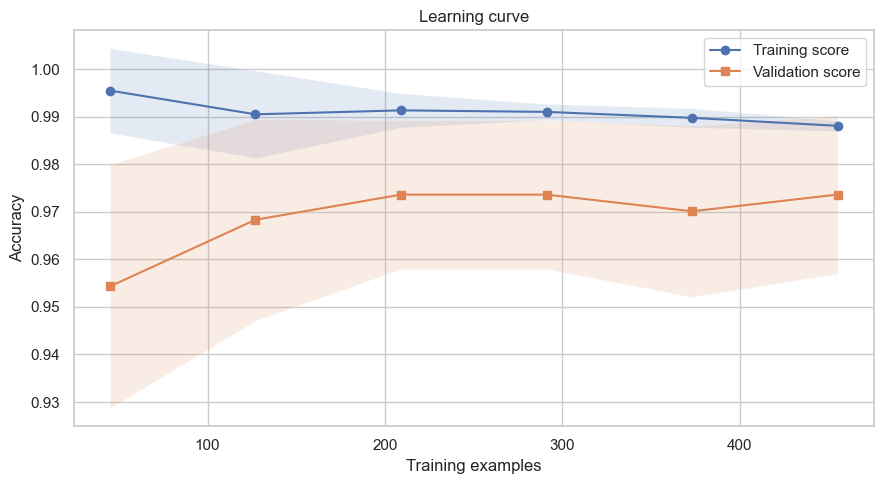

In [8]:
train_sizes, train_scores, val_scores = learning_curve(
    model, X, y, cv=cv, scoring="accuracy",
    train_sizes=np.linspace(0.1, 1.0, 6), n_jobs=-1, shuffle=True, random_state=RANDOM_STATE
)

train_mean = train_scores.mean(axis=1)
train_std = train_scores.std(axis=1)
val_mean = val_scores.mean(axis=1)
val_std = val_scores.std(axis=1)

plt.figure(figsize=(9, 5))
plt.plot(train_sizes, train_mean, marker="o", label="Training score")
plt.fill_between(train_sizes, train_mean - train_std, train_mean + train_std, alpha=0.15)
plt.plot(train_sizes, val_mean, marker="s", label="Validation score")
plt.fill_between(train_sizes, val_mean - val_std, val_mean + val_std, alpha=0.15)
plt.xlabel("Training examples")
plt.ylabel("Accuracy")
plt.title("Learning curve")
plt.legend()
plt.tight_layout()
plt.show()

## 7. Regression metrics

Classification metrics do not apply to continuous targets. We use the diabetes dataset to compare
MAE, MSE, RMSE, and R² for a linear regression model.

In [9]:
diabetes = load_diabetes(as_frame=True)
Xr, yr = diabetes.data, diabetes.target

Xr_train, Xr_test, yr_train, yr_test = train_test_split(
    Xr, yr, test_size=0.25, random_state=RANDOM_STATE
)

regressor = LinearRegression()
regressor.fit(Xr_train, yr_train)
yr_pred = regressor.predict(Xr_test)

reg_metrics = {
    "MAE": mean_absolute_error(yr_test, yr_pred),
    "MSE": mean_squared_error(yr_test, yr_pred),
    "RMSE": np.sqrt(mean_squared_error(yr_test, yr_pred)),
    "R2": r2_score(yr_test, yr_pred),
}
pd.Series(reg_metrics).round(3)

MAE       41.549
MSE     2848.311
RMSE      53.370
R2         0.485
dtype: float64

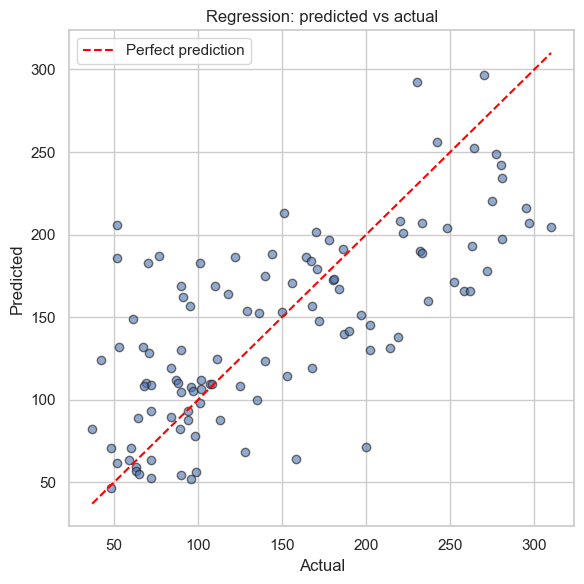

In [10]:
plt.figure(figsize=(6, 6))
plt.scatter(yr_test, yr_pred, alpha=0.6, edgecolor="k")
lims = [min(yr_test.min(), yr_pred.min()), max(yr_test.max(), yr_pred.max())]
plt.plot(lims, lims, "--", color="red", label="Perfect prediction")
plt.xlabel("Actual")
plt.ylabel("Predicted")
plt.title("Regression: predicted vs actual")
plt.legend()
plt.tight_layout()
plt.show()

## 8. Common evaluation mistakes

1. **Data leakage** - fitting a scaler, imputer, or feature selector on the full dataset before splitting.
   Use pipelines and split first.
2. **Tuning on the test set** - repeated test-set checks turn it into a validation set. Keep a final
   test set untouched.
3. **Accuracy on imbalanced data** - a 95% majority-class predictor can look excellent while missing
   every minority case.
4. **Ignoring variability** - a single split can be lucky. Report cross-validation mean and standard deviation.
5. **Wrong metric** - optimising RMSE when large errors are unacceptable, or accuracy when recall matters.
6. **Comparing models on different splits** - always use the same folds for a fair comparison.

## Key takeaways

- Pick the metric first, then the model.
- Use cross-validation and report variability.
- ROC-AUC measures ranking; PR-AUC is better for rare positives.
- Learning curves separate underfitting from overfitting.
- Keep a final hold-out test set that you do not tune against.

## Exercises

1. Create an imbalanced version of the breast-cancer target and compare accuracy, F1, and PR-AUC.
2. Plot the same ROC curve for a random forest and a logistic regression. Which ranks better?
3. Use `RepeatedStratifiedKFold` and compare the variance of the scores.
4. Compute a 95% bootstrap confidence interval for test accuracy.
5. Explain why `cross_val_score(model, X, y)` with a scaler fitted before the call is a leakage bug.
6. On the diabetes data, compare MAE and RMSE. What does the difference tell you about the residuals?